# Baseline models: teaching interaction quality

## Audrey Xiao, Sydney Luciano, Charles Ross

## Github Repo: https://github.com/axiao23/CSCI3345-TeachingEvaluatorModel

Trains four simple baselines on the teacher-level split and scores them on validation and test. Run from the repo root so `data/` and `results/` resolve. Seed 42.

In [ ]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix,
                             f1_score, mean_absolute_error)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

os.makedirs("results", exist_ok=True)
SEED = 42
TARGET = "teaching_quality_class"
ORDER = ["Poor", "Needs Improvement", "Average", "Good", "Excellent"]
LABEL = {k: i for i, k in enumerate(ORDER)}

## Load data

Cleaned, unscaled splits. Scaling happens inside the logistic regression pipeline, fit on train only.

In [ ]:
tr, va, te = (pd.read_csv(f"data/{s}.csv") for s in ("train", "val", "test"))
FEATS = [c for c in tr.columns if c != TARGET]
print(len(FEATS), "features;", len(tr), len(va), len(te), "rows")
tr[TARGET].value_counts().reindex(ORDER)

32 features; 10699 2150 2151 rows


teaching_quality_class
Poor                 1159
Needs Improvement    1918
Average              3009
Good                 2783
Excellent            1830
Name: count, dtype: int64

## Models and metrics

Macro-F1 is the main metric. Accuracy, quadratic weighted kappa and MAE in label levels are there because the classes are ordered.

In [ ]:
def xy(df, feats):
    return df[feats].values, df[TARGET].map(LABEL).values

def models():
    return {
        "Majority class": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        "Random forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
        "Hist. gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
    }

def scores(y, p):
    return {
        "macro_f1": f1_score(y, p, average="macro"),
        "accuracy": accuracy_score(y, p),
        "qw_kappa": cohen_kappa_score(y, p, weights="quadratic"),
        "mae_levels": mean_absolute_error(y, p),
    }

def run(feats, tag):
    Xtr, ytr = xy(tr, feats); Xva, yva = xy(va, feats); Xte, yte = xy(te, feats)
    rows, fitted = [], {}
    for name, m in models().items():
        m.fit(Xtr, ytr)
        fitted[name] = m
        rows.append({"model": name, "feature_set": tag,
                     **{f"val_{k}": v for k, v in scores(yva, m.predict(Xva)).items()},
                     **{f"test_{k}": v for k, v in scores(yte, m.predict(Xte)).items()}})
    return pd.DataFrame(rows), fitted

## Run baselines

Once with all 32 features, once without `overall_interaction_score` (a composite of other columns and the strongest single predictor).

In [ ]:
res_all, fit_all = run(FEATS, "all 32 features")
no_overall = [f for f in FEATS if f != "overall_interaction_score"]
res_no, _ = run(no_overall, "without overall_interaction_score")
res = pd.concat([res_all, res_no], ignore_index=True)
res.round(4).to_csv("results/baseline_results.csv", index=False)
res.round(3)

,model,feature_set,val_macro_f1,val_accuracy,val_qw_kappa,val_mae_levels,test_macro_f1,test_accuracy,test_qw_kappa,test_mae_levels
0,Majority class,all 32 features,0.086,0.273,0.000,1.009,0.088,0.281,0.000,1.000
1,Logistic regression,all 32 features,0.715,0.700,0.906,0.300,0.724,0.708,0.904,0.295
2,Random forest,all 32 features,0.714,0.697,0.902,0.305,0.724,0.706,0.903,0.295
3,Hist. gradient boosting,all 32 features,0.709,0.691,0.898,0.309,0.715,0.698,0.896,0.305
4,Majority class,without overall_interaction_score,0.086,0.273,0.000,1.009,0.088,0.281,0.000,1.000
5,Logistic regression,without overall_interaction_score,0.716,0.700,0.906,0.300,0.721,0.705,0.903,0.298
6,Random forest,without overall_interaction_score,0.722,0.705,0.904,0.296,0.731,0.715,0.905,0.286
7,Hist. gradient boosting,without overall_interaction_score,0.715,0.696,0.898,0.306,0.719,0.705,0.899,0.297


## Error analysis

Best model by validation macro-F1 (all features). How far off are the mistakes, and which classes get confused?

In [ ]:
best = res_all.sort_values("val_macro_f1").iloc[-1]["model"]
m = fit_all[best]
Xva, yva = xy(va, FEATS)
pva = m.predict(Xva)
cm = confusion_matrix(yva, pva)
pd.DataFrame(cm, index=ORDER, columns=ORDER).to_csv("results/confusion_val.csv")
off = np.abs(yva - pva)
summary = {
    "best_model_by_val_macro_f1": best,
    "per_class_f1_val": dict(zip(ORDER, f1_score(yva, pva, average=None).round(3).tolist())),
    "share_exact": float((off == 0).mean()),
    "share_off_by_one": float((off == 1).mean()),
    "share_off_by_two_or_more": float((off >= 2).mean()),
}
json.dump(summary, open("results/error_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "best_model_by_val_macro_f1": "Logistic regression",
  "per_class_f1_val": {
    "Poor": 0.806,
    "Needs Improvement": 0.662,
    "Average": 0.657,
    "Good": 0.661,
    "Excellent": 0.787
  },
  "share_exact": 0.7,
  "share_off_by_one": 0.29953488372093023,
  "share_off_by_two_or_more": 0.00046511627906976747
}


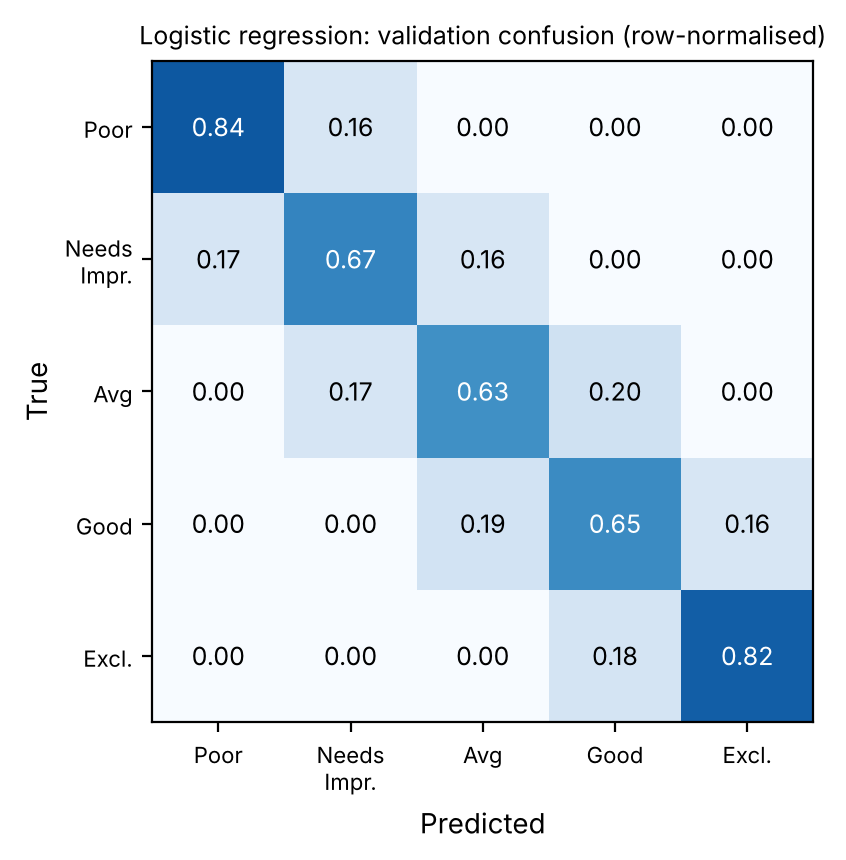

In [ ]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
cmn = cm / cm.sum(axis=1, keepdims=True)
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
short = ["Poor", "Needs\nImpr.", "Avg", "Good", "Excl."]
ax.set_xticks(range(5), short, fontsize=8)
ax.set_yticks(range(5), short, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"{best}: validation confusion (row-normalised)", fontsize=9)
plt.tight_layout()
plt.savefig("results/confusion_val.png", dpi=200)
plt.show()

## Feature importance (random forest)

In [ ]:
rf = fit_all["Random forest"]
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values(ascending=False)
imp.round(4).to_csv("results/rf_importance.csv", header=["importance"])
imp.head(10).round(3)

overall_interaction_score        0.119
classroom_communication_score    0.083
interaction_consistency_score    0.078
teacher_feedback_score           0.062
student_engagement_level         0.061
contextual_engagement_score      0.060
attention_score                  0.049
student_participation_rate       0.042
positive_behavior_ratio          0.037
interaction_intensity            0.035
dtype: float64